# 🍄 버섯 식용/독성 분류: 과제 1~7단계 (프로젝트 ① 분류 데이터)

1. 범주형 변수 인코딩 (LabelEncoding · One-Hot Encoding)
2. X, y 변수를 새 DataFrame으로 추출
3. train_test_split으로 데이터 분리
4. fit() · predict()로 예측 (DecisionTree · RandomForest)
5. 교차검증 후 정확도 비교 (KFold · Stratified KFold)
6. GridSearchCV로 정확도 비교 · 최적 파라미터 탐색
7. 파라미터 선택 이유 → PPT에 작성

**사용법 (구글 코랩)**: 맨 위 셀부터 **Shift + Enter**로 하나씩 실행하세요. `mushrooms.csv`가 없으면 [0] 셀이 업로드 창을 띄워요.
**[13]부터가 새로 추가된 5~7단계**예요. 1~4단계 셀([0]~[12])을 먼저 실행해야 `X_train`, `dt`, `rf` 등이 만들어져서 이어서 쓸 수 있어요.

### [0] 준비: 라이브러리 · 파일 · 한글 글꼴

In [1]:
import os, sys, subprocess
import pandas as pd                 # 표(DataFrame)를 다루는 도구
import numpy as np                  # 숫자 계산 도구
import matplotlib.pyplot as plt     # 그래프 도구
import seaborn as sns               # 통계 그래프 도구

# mushrooms.csv가 현재 폴더에 있는지 확인 → 없으면 sample_data 안을 찾고 → 그래도 없으면 업로드 창
if not os.path.exists('mushrooms.csv'):
    if os.path.exists('sample_data/mushrooms.csv'):
        os.rename('sample_data/mushrooms.csv', 'mushrooms.csv')     # 폴더 안에 잘못 들어간 파일을 밖으로
    else:
        try:
            from google.colab import files                         # 코랩 전용 업로드 도구
            print('[파일 선택] 버튼을 눌러 mushrooms.csv를 골라 주세요.')
            files.upload()
        except ImportError:
            sys.exit('mushrooms.csv를 이 파일과 같은 폴더에 넣어 주세요.')
print('mushrooms.csv 준비 완료:', os.path.exists('mushrooms.csv'))

# 그래프 한글 글꼴 (없으면 자동 설치)
try:
    import koreanize_matplotlib
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'koreanize-matplotlib'])
    try:
        import koreanize_matplotlib
    except ImportError:
        print('한글 글꼴 설치 실패: 그래프의 한글만 깨지고 나머지는 정상이에요.')
plt.rcParams['axes.unicode_minus'] = False

os.makedirs('figures', exist_ok=True)   # 그래프 이미지를 저장할 폴더 (PPT에 넣기 좋게)

mushrooms.csv 준비 완료: True


### [1] 1단계-①: 데이터 읽기 · veil-type 삭제 · '?' 유지

In [2]:
df = pd.read_csv('mushrooms.csv')            # 원본 (8124, 23)
print('원본:', df.shape)

if 'veil-type' in df.columns:                # 두 번 실행해도 에러 나지 않게 '남아 있을 때만' 삭제
    df = df.drop('veil-type', axis=1)        # 모든 버섯이 같은 값(p) → 구분에 쓸모없음
print('veil-type 삭제 후:', df.shape)        # (8124, 22)

# stalk-root의 '?'(결측)는 지우지 않고 하나의 범주로 둠 → '?'인 버섯의 71%가 독성이라 빈칸 자체가 단서
print(df['stalk-root'].value_counts())

원본: (8124, 23)
veil-type 삭제 후: (8124, 22)
stalk-root
b    3776
?    2480
e    1120
c     556
r     192
Name: count, dtype: int64


### [2] 1단계-②: 정답(class) → 레이블 인코딩

In [3]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()                                 # '글자 → 번호' 변환기
df['class'] = encoder.fit_transform(df['class'])         # fit(값 종류 배우기) + transform(번호로 바꾸기)
mapping = {label: num for num, label in enumerate(encoder.classes_)}
print('변환 규칙:', mapping)                             # {'e': 0, 'p': 1} → 0 = 식용, 1 = 독성
print(df['class'].value_counts())                        # 0: 4208, 1: 3916

변환 규칙: {'e': 0, 'p': 1}
class
0    4208
1    3916
Name: count, dtype: int64


### [3] 1단계-③: 특성 21개 → 원-핫 인코딩 (메인)

In [4]:
X_onehot = pd.get_dummies(df.drop('class', axis=1), dtype=int)
# df.drop('class', axis=1) : 정답을 뺀 특성 21개
# pd.get_dummies(...)      : 값마다 0/1 열을 만듦 (원-핫)
# dtype=int                : True/False 대신 1/0
print('원-핫 전:', df.drop('class', axis=1).shape)       # (8124, 21)
print('원-핫 후:', X_onehot.shape)                       # (8124, 116)

odor_cols = [c for c in X_onehot.columns if c.startswith('odor_')]
print(X_onehot[odor_cols].head(3))                       # 행마다 자기 냄새 칸 하나만 1

원-핫 전: (8124, 21)
원-핫 후: (8124, 116)
   odor_a  odor_c  odor_f  odor_l  odor_m  odor_n  odor_p  odor_s  odor_y
0       0       0       0       0       0       0       1       0       0
1       1       0       0       0       0       0       0       0       0
2       0       0       0       1       0       0       0       0       0


### [4] 1단계-④: (비교용) 특성 21개 → 레이블 인코딩

In [5]:
X_label = df.drop('class', axis=1).apply(lambda col: LabelEncoder().fit_transform(col))
# .apply(함수): 열마다 같은 함수를 적용 / 각 열의 글자를 알파벳 순서대로 0, 1, 2 … 로
print('레이블 인코딩 후:', X_label.shape)                # (8124, 21) → 열 수 그대로

레이블 인코딩 후: (8124, 21)


### [5] 2단계: X, y를 새 DataFrame으로 추출

In [6]:
X = X_onehot.copy()          # 특성(문제지): 원-핫 116열 DataFrame. copy()로 원본 보호
y = df['class']              # 정답(정답지): 0/1 한 열 (Series)

print('X:', type(X).__name__, X.shape)                   # DataFrame (8124, 116)
print('y:', type(y).__name__, y.shape)                   # Series (8124,)
print('행 짝이 맞는가?', (X.index == y.index).all())     # True
print(y.to_frame().head(3))                              # y를 DataFrame 모양으로도 확인

X: DataFrame (8124, 116)
y: Series (8124,)
행 짝이 맞는가? True
   class
0      1
1      0
2      0


### [6] 3단계: train_test_split으로 학습/테스트 분리

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 테스트 20% (1,625개)
    random_state=42,     # 누가 몇 번 실행해도 같은 결과
    stratify=y           # 학습·테스트 모두 식용:독성 비율을 원본과 같게
)
print('X_train:', X_train.shape, '| X_test:', X_test.shape)   # (6499, 116) | (1625, 116)
print(f'독성 비율  전체 {y.mean():.2%} / 학습 {y_train.mean():.2%} / 테스트 {y_test.mean():.2%}')
print('테스트 정답 개수:', y_test.value_counts().to_dict())   # {0: 842, 1: 783}

X_train: (6499, 116) | X_test: (1625, 116)
독성 비율  전체 48.20% / 학습 48.21% / 테스트 48.18%
테스트 정답 개수: {0: 842, 1: 783}


### [7] 4단계-①: 결정 트리 학습(fit) → 예측(predict) → 채점

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score

dt = DecisionTreeClassifier(random_state=42)   # 모델 만들기 (기본 설정)
dt.fit(X_train, y_train)                       # 학습: 문제집 + 정답으로 규칙을 배움
pred = dt.predict(X_test)                      # 예측: 처음 보는 시험지의 정답을 맞힘

print(pd.DataFrame({'실제': y_test.values[:10], '예측': pred[:10]}).T)   # 앞 10개 비교
print('테스트 정확도:', accuracy_score(y_test, pred))
print('학습 정확도  :', accuracy_score(y_train, dt.predict(X_train)))
print('독성 재현율  :', recall_score(y_test, pred))   # 실제 독버섯 중 '독성'으로 찾아낸 비율

    0  1  2  3  4  5  6  7  8  9
실제  1  1  0  1  1  0  0  0  0  1
예측  1  1  0  1  1  0  0  0  0  1
테스트 정확도: 1.0
학습 정확도  : 1.0
독성 재현율  : 1.0


### [8] 4단계-②: 혼동행렬 그래프

[[842   0]
 [  0 783]]


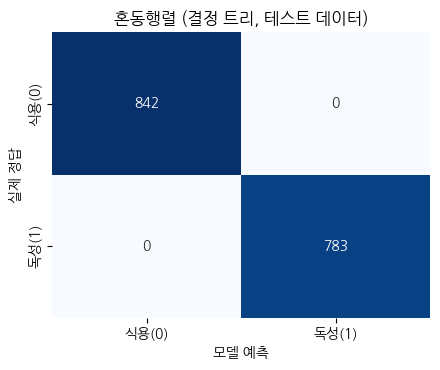

In [9]:
cm = confusion_matrix(y_test, pred)            # [[식용→식용, 식용→독성], [독성→식용, 독성→독성]]
print(cm)

fig, ax = plt.subplots(figsize=(4.5, 3.8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['식용(0)', '독성(1)'], yticklabels=['식용(0)', '독성(1)'])
ax.set_xlabel('모델 예측'); ax.set_ylabel('실제 정답')
ax.set_title('혼동행렬 (결정 트리, 테스트 데이터)')
plt.tight_layout(); plt.savefig('figures/confusion_matrix.png', dpi=200); plt.show()

### [9] 4단계-③: 특성 중요도 그래프

odor_n                        0.618
stalk-root_c                  0.179
stalk-surface-below-ring_y    0.099
spore-print-color_r           0.036
odor_a                        0.023
dtype: float64


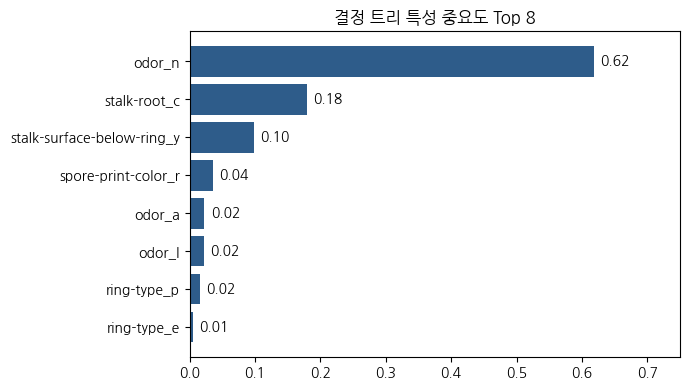

In [10]:
imp = pd.Series(dt.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(5).round(3))                    # 모두 더하면 1

top = imp.head(8)[::-1]                        # 상위 8개 (큰 값이 위로 오게 뒤집음)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top.index, top.values, color='#2E5C8A')
for i, v in enumerate(top.values):
    ax.text(v + 0.01, i, f'{v:.2f}', va='center')
ax.set_xlim(0, 0.75); ax.set_title('결정 트리 특성 중요도 Top 8')
plt.tight_layout(); plt.savefig('figures/feature_importance.png', dpi=200); plt.show()

### [10] 4단계-④: 결정 트리 그림 (위쪽 3단계만)

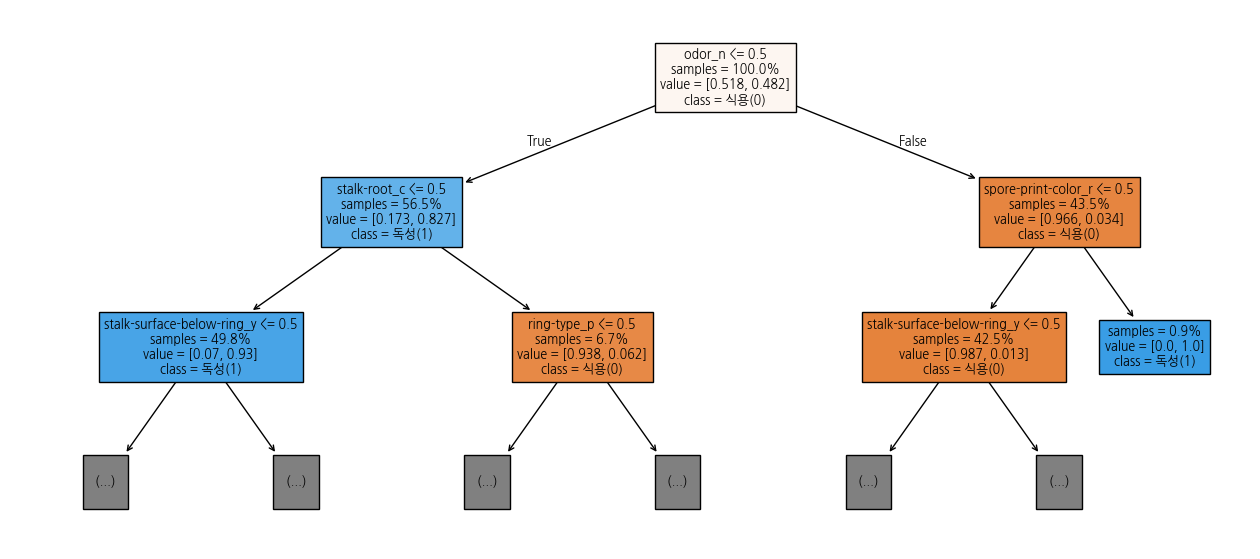

트리 깊이: 7 / 잎 개수: 14


In [11]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(dt, max_depth=2, feature_names=X.columns, class_names=['식용(0)', '독성(1)'],
          filled=True, impurity=False, proportion=True, fontsize=9, ax=ax)
plt.savefig('figures/decision_tree.png', dpi=150, bbox_inches='tight'); plt.show()
print('트리 깊이:', dt.get_depth(), '/ 잎 개수:', dt.get_n_leaves())

### [11] 4단계-⑤: 비교 — 랜덤 포레스트, 레이블 인코딩 버전

In [12]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42).fit(X_train, y_train)        # 트리 100개의 다수결
rf_acc = accuracy_score(y_test, rf.predict(X_test))

XL_train, XL_test, yL_train, yL_test = train_test_split(                  # 레이블 인코딩 특성도 같은 조건으로 분리
    X_label, y, test_size=0.2, random_state=42, stratify=y)
dt_label = DecisionTreeClassifier(random_state=42).fit(XL_train, yL_train)
label_acc = accuracy_score(yL_test, dt_label.predict(XL_test))

print(pd.DataFrame({'특성 인코딩': ['원-핫(116열)', '원-핫(116열)', '레이블(21열)'],
                    '모델': ['결정 트리', '랜덤 포레스트', '결정 트리'],
                    '테스트 정확도': [accuracy_score(y_test, pred), rf_acc, label_acc]}))

      특성 인코딩       모델  테스트 정확도
0  원-핫(116열)    결정 트리      1.0
1  원-핫(116열)  랜덤 포레스트      1.0
2   레이블(21열)    결정 트리      1.0


### [12] (보너스) max_depth별 성능 · 냄새를 뺀 실험

In [13]:
rows = []
for depth in [1, 2, 3, 4, 5, None]:                    # None = 제한 없음(기본값)
    m = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append({'max_depth': '제한 없음' if depth is None else depth,
                 '정확도': round(accuracy_score(y_test, p), 4),
                 '독성 재현율': round(recall_score(y_test, p), 4),
                 '놓친 독버섯': int(confusion_matrix(y_test, p)[1, 0])})
print(pd.DataFrame(rows))

no_odor = [c for c in X.columns if not c.startswith('odor_')]                  # odor 9개 열 제외
dt_no_odor = DecisionTreeClassifier(random_state=42).fit(X_train[no_odor], y_train)
print('냄새 없이 정확도:', accuracy_score(y_test, dt_no_odor.predict(X_test[no_odor])))

  max_depth     정확도  독성 재현율  놓친 독버섯
0         1  0.8855  0.9706      23
1         2  0.9489  0.9732      21
2         3  0.9822  0.9962       3
3         4  0.9914  0.9974       2
4         5  0.9988  0.9974       2
5     제한 없음  1.0000  1.0000       0
냄새 없이 정확도: 1.0


---
## 5단계. 교차검증 (KFold · Stratified KFold)

4단계의 100%는 **시험지 한 장(테스트 1,625개)** 으로 잰 점수예요. 우연히 쉬운 시험지였을 수도 있으니, **학습 데이터(6,499개)를 5조각으로 나눠 시험을 5번** 보고 평균을 내요.

| 방식 | 나누는 법 | 특징 |
|---|---|---|
| KFold | 섞은 뒤 5등분 | 조각마다 식용:독성 비율이 조금씩 다를 수 있음 |
| Stratified KFold | 5등분하되 **조각마다 식용:독성 비율을 똑같이** 유지 | 분류 문제에 기본으로 추천 |

⚠️ 교차검증은 **`X_train`, `y_train`만** 써요. 테스트 데이터는 마지막 채점용으로 아껴 둬요.

### [13] 5단계-①: KFold vs Stratified KFold 점수 (결정 트리 · 랜덤 포레스트)

In [14]:
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score

kf  = KFold(n_splits=5, shuffle=True, random_state=42)             # 그냥 5등분
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # 클래스 비율을 지키며 5등분

models = {'결정 트리': DecisionTreeClassifier(random_state=42),
          '랜덤 포레스트': RandomForestClassifier(random_state=42)}

fold_scores, cv_rows = {}, []
for name, model in models.items():
    for cv_name, cv in [('KFold', kf), ('StratifiedKFold', skf)]:
        s = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')   # 5번 학습·채점 → 점수 5개
        fold_scores[(name, cv_name)] = s
        cv_rows.append({'모델': name, '분할 방식': cv_name,
                        '평균': round(s.mean(), 4), '표준편차': round(s.std(), 4),
                        '폴드별 점수': s.round(4).tolist()})
cv_table = pd.DataFrame(cv_rows)
print(cv_table.to_string(index=False))

     모델           분할 방식     평균   표준편차                       폴드별 점수
  결정 트리           KFold 0.9998 0.0003 [1.0, 1.0, 1.0, 0.9992, 1.0]
  결정 트리 StratifiedKFold 0.9997 0.0006 [0.9985, 1.0, 1.0, 1.0, 1.0]
랜덤 포레스트           KFold 1.0000 0.0000    [1.0, 1.0, 1.0, 1.0, 1.0]
랜덤 포레스트 StratifiedKFold 1.0000 0.0000    [1.0, 1.0, 1.0, 1.0, 1.0]


### [14] 5단계-②: 폴드별 점수 그래프

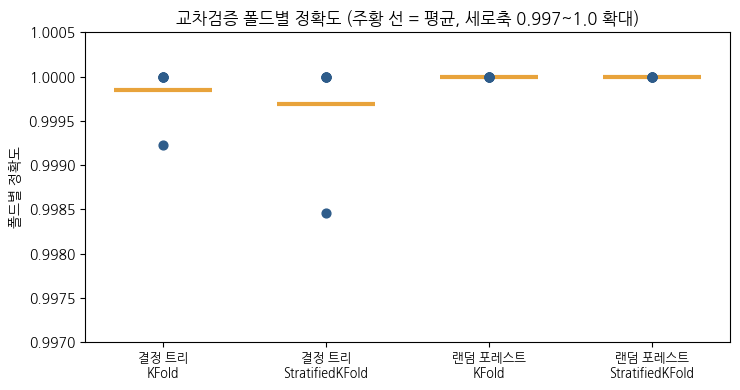

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 4))
labels = []
for i, ((name, cv_name), s) in enumerate(fold_scores.items()):
    ax.scatter([i] * len(s), s, color='#2E5C8A', s=40, zorder=3)              # 파란 점 = 폴드 하나의 점수
    ax.hlines(s.mean(), i - 0.3, i + 0.3, color='#E8A33B', lw=3, zorder=2)    # 주황 선 = 평균
    labels.append(f'{name}\n{cv_name}')
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=9)
ax.set_ylim(0.997, 1.0005); ax.set_ylabel('폴드별 정확도')
ax.set_title('교차검증 폴드별 정확도 (주황 선 = 평균, 세로축 0.997~1.0 확대)')
plt.tight_layout(); plt.savefig('figures/cv_scores.png', dpi=200); plt.show()

---
## 6단계. GridSearchCV로 최적 파라미터 탐색

4단계에서 **max_depth(질문 최대 횟수)** 를 바꾸면 성능이 달라지는 걸 봤어요. 어떤 값이 제일 좋은지 직접 하나씩 시험하는 대신, **GridSearchCV** 가 **후보 조합을 전부 시험**해서 가장 좋은 조합을 찾아 줘요.

- 조합마다 5단계의 교차검증(Stratified 5-fold)으로 점수를 매겨요. (후보 12개 × 5번 = 60번 학습)
- 점수가 가장 높은 조합이 `best_params_`, 그 점수가 `best_score_`예요.
- 학습 데이터(`X_train`)로만 탐색해요. 테스트 데이터는 마지막 채점에만 써요.

### [15] 6단계-①: GridSearchCV로 결정 트리 최적 파라미터 탐색

In [16]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [2, 3, 4, 5, 6, None],    # 질문 최대 횟수 (None = 제한 없음)
    'criterion': ['gini', 'entropy'],      # 칸을 나누는 기준
}

gs = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid,
                  cv=skf, scoring='accuracy')     # skf: [13]에서 만든 Stratified 5-fold
gs.fit(X_train, y_train)                          # 학습 데이터로만 탐색

print('선택된 설정      :', gs.best_params_)
print('교차검증 정확도  :', round(gs.best_score_, 4))

선택된 설정      : {'criterion': 'gini', 'max_depth': 5}
교차검증 정확도  : 0.9997


### [16] 6단계-②: 조합별 교차검증 점수 (위에서부터 점수 높은 순)

In [17]:
cv_df = pd.DataFrame(gs.cv_results_)
cols = ['param_max_depth', 'param_criterion', 'mean_test_score', 'rank_test_score']
print(cv_df[cols].sort_values('rank_test_score').head(8).round(4).to_string(index=False))

param_max_depth param_criterion  mean_test_score  rank_test_score
              5            gini           0.9997                1
              6            gini           0.9997                1
           None            gini           0.9997                1
              5         entropy           0.9997                1
              6         entropy           0.9997                1
           None         entropy           0.9997                1
              4            gini           0.9926                7
              4         entropy           0.9883                8


### [17] 6단계-③: 점수 비교표 (기본 → 교차검증 평균 → 튜닝 후)

팀 PPT의 **점수 비교표(분류)** 를 채우는 셀이에요. 테스트 점수는 **마지막에 딱 한 번** 재요.

In [18]:
best_dt = gs.best_estimator_                       # 최적 설정으로 학습이 끝난 모델
base_pred = dt.predict(X_test)                     # 4단계 기본 모델 (튜닝 전)
tuned_pred = best_dt.predict(X_test)               # 튜닝 후 모델

score_table = pd.DataFrame({
    '단계': ['① 기본 모델 (테스트)', '② 교차검증 평균 (Stratified 5)', '③ 튜닝 후 (교차검증)', '③ 튜닝 후 (테스트)'],
    '정확도': [accuracy_score(y_test, base_pred),
              fold_scores[('결정 트리', 'StratifiedKFold')].mean(),
              gs.best_score_,
              accuracy_score(y_test, tuned_pred)],
})
print(score_table.round(4).to_string(index=False))
print('놓친 독버섯 (기본 → 튜닝 후):', confusion_matrix(y_test, base_pred)[1, 0], '→', confusion_matrix(y_test, tuned_pred)[1, 0])
score_table.to_csv('figures/score_table.csv', index=False, encoding='utf-8-sig')

                      단계    정확도
           ① 기본 모델 (테스트) 1.0000
② 교차검증 평균 (Stratified 5) 0.9997
           ③ 튜닝 후 (교차검증) 0.9997
            ③ 튜닝 후 (테스트) 0.9988
놓친 독버섯 (기본 → 튜닝 후): 0 → 2


---
## 7단계. 파라미터 선택 이유 (PPT에 쓸 근거 만들기)

"왜 이 값을 골랐나요?"에 **숫자로 답할 수 있게** 근거를 모아요. 테스트 데이터가 아니라 **교차검증 점수**로 골랐다는 점이 중요해요.

### [18] 7단계-①: max_depth별 교차검증 점수 그래프

max_depth  교차검증 정확도
     깊이 1    0.8871
     깊이 2    0.9555
     깊이 3    0.9860
     깊이 4    0.9926
     깊이 5    0.9997
     깊이 6    0.9997
    제한 없음    0.9997


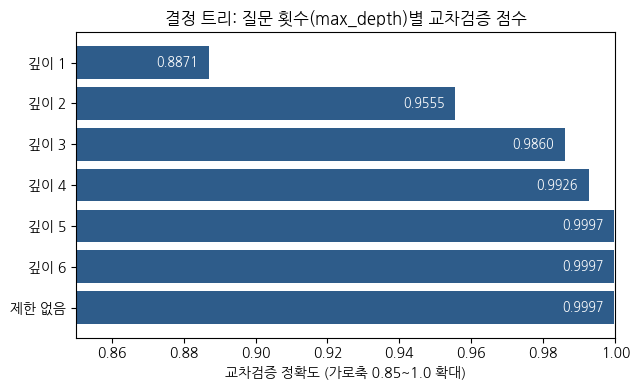

In [19]:
depths = [1, 2, 3, 4, 5, 6, None]
cv_depth = [cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=42),
                            X_train, y_train, cv=skf, scoring='accuracy').mean() for d in depths]
names = ['제한 없음' if d is None else f'깊이 {d}' for d in depths]
print(pd.DataFrame({'max_depth': names, '교차검증 정확도': np.round(cv_depth, 4)}).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.barh(names[::-1], cv_depth[::-1], color='#2E5C8A')
for i, v in enumerate(cv_depth[::-1]):
    ax.text(v - 0.003, i, f'{v:.4f}', va='center', ha='right', color='white', fontsize=9)
ax.set_xlim(0.85, 1.0); ax.set_xlabel('교차검증 정확도 (가로축 0.85~1.0 확대)')
ax.set_title('결정 트리: 질문 횟수(max_depth)별 교차검증 점수')
plt.tight_layout(); plt.savefig('figures/depth_cv.png', dpi=200); plt.show()

### [19] 7단계-②: 설정값별 최고 점수 (어떤 값이 점수를 바꿨나?)

In [20]:
for p in ['param_max_depth', 'param_criterion']:
    key = cv_df[p].apply(lambda v: 'None' if v is None else str(v))          # None도 글자로 바꿔서 함께 집계
    g = cv_df.groupby(key)['mean_test_score'].max().round(4)                 # 그 값을 쓴 조합 중 최고 점수
    print(f"{p.replace('param_', ''):10s}", ' | '.join(f'{k}: {v}' for k, v in g.items()))

max_depth  2: 0.9555 | 3: 0.986 | 4: 0.9926 | 5: 0.9997 | 6: 0.9997 | None: 0.9997
criterion  entropy: 0.9997 | gini: 0.9997


### [20] 7단계-③: 선택 이유 정리 → PPT에 옮길 문구

(아래 표는 [15]~[19] 결과를 본 뒤 옮긴 거예요. 숫자가 다르면 셀을 다시 실행해서 확인하세요.)

| 파라미터 | 후보 | 선택 | 선택 이유 |
|---|---|---|---|
| `max_depth` | 2·3·4·5·6·None | **5** | 깊이 1~4는 점수가 계속 오르지만(88.7%→99.3%), **5부터 99.97%에서 멈춤** → 더 깊게 키울 이유가 없음. 깊이 5·6·제한 없음이 동점이라 가장 단순한 5를 선택 |
| `criterion` | gini·entropy | **gini** | 두 기준의 최고 점수가 같음(99.97%) → 계산이 더 빠른 gini |

**선택 기준**: 교차검증 정확도가 가장 높은 조합 → 동점이면 더 단순한 설정. 테스트 점수는 고르는 데 쓰지 않았어요.

**해석 시 주의할 점 (발표 대비)**

- 튜닝 후 테스트 정확도(99.88%)가 기본 모델(100%)보다 아주 조금 낮아요. 테스트 1,625개 중 **2개** 차이예요. 교차검증 점수는 둘 다 99.97%로 같아서(깊이 5·6·제한 없음이 동점), 한 번 나눈 시험지에서 생긴 오차 수준이에요. 테스트 점수가 더 좋은 쪽을 고르면 "시험지를 보고 답을 고른" 셈이라 하지 않았어요.
- 이 데이터는 규칙이 뚜렷해서 점수가 거의 천장(100%)이에요. 그래서 튜닝의 의미는 점수를 올리는 게 아니라 **"깊이 5면 충분하다"는 근거**를 얻는 거예요.